# EXPT NO: 6
# IMPLEMENTATION OF LSTM FOR SENTIMENT ANALYSIS
**Student Roll No:** 24BAD108


## Part A – Dataset Preparation and Text Preprocessing

In [1]:
# Cell 1: Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully.")


TensorFlow version: 2.20.0
Libraries imported successfully.


In [2]:
# Cell 2: Load the IMDB Dataset

NUM_WORDS = 10000

(X_train_full, y_train_full), (X_test_full, y_test_full) = imdb.load_data(
    num_words=NUM_WORDS
)

print("Original training samples:", len(X_train_full))
print("Original testing samples :", len(X_test_full))


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Original training samples: 25000
Original testing samples : 25000


In [3]:
# Cell 3: Use a Smaller Dataset for Faster Training

# A smaller subset is used to make this lab faster in Google Colab.
TRAIN_SAMPLES = 5000
TEST_SAMPLES = 1000

X_train_full = X_train_full[:TRAIN_SAMPLES]
y_train_full = y_train_full[:TRAIN_SAMPLES]

X_test = X_test_full[:TEST_SAMPLES]
y_test = y_test_full[:TEST_SAMPLES]

print("Training samples:", len(X_train_full))
print("Testing samples :", len(X_test))


Training samples: 5000
Testing samples : 1000


In [4]:
# Cell 4: Explore the Dataset

print("First encoded review:")
print(X_train_full[0][:30])

print("\nFirst sentiment label:")
print(y_train_full[0])

print("\nClass distribution:")
print("Negative reviews:", np.sum(y_train_full == 0))
print("Positive reviews:", np.sum(y_train_full == 1))

print("\nFirst 5 review lengths:")
for i in range(5):
    print(f"Review {i+1}: {len(X_train_full[i])} words/tokens")


First encoded review:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480]

First sentiment label:
1

Class distribution:
Negative reviews: 2454
Positive reviews: 2546

First 5 review lengths:
Review 1: 218 words/tokens
Review 2: 189 words/tokens
Review 3: 141 words/tokens
Review 4: 550 words/tokens
Review 5: 147 words/tokens


In [5]:
# Cell 5: Decode an IMDB Review for Inspection

word_index = imdb.get_word_index()
reverse_word_index = {value: key for key, value in word_index.items()}

def decode_review(encoded_review):
    words = []
    for index in encoded_review:
        # IMDB reserves 0-3 for special tokens.
        if index >= 4:
            word = reverse_word_index.get(index - 3, "?")
            words.append(word)
    return " ".join(words)

print("Decoded sample review:")
print(decode_review(X_train_full[0]))

print("\nActual label:")
print("Positive" if y_train_full[0] == 1 else "Negative")


1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Decoded sample review:
this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also to the two little boy's that played the of norman and paul they were just brilliant children are often left out of the list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing a

In [6]:
# Cell 6: Sequence Padding

MAX_LEN = 150

X_train_padded = pad_sequences(
    X_train_full,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_padded = pad_sequences(
    X_test,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Padded training shape:", X_train_padded.shape)
print("Padded testing shape :", X_test_padded.shape)


Padded training shape: (5000, 150)
Padded testing shape : (1000, 150)


In [7]:
# Cell 7: Train-Validation Split

X_train, X_val, y_train, y_val = train_test_split(
    X_train_padded,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)

print("Training data  :", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data   :", X_test_padded.shape)


Training data  : (4000, 150)
Validation data: (1000, 150)
Testing data   : (1000, 150)


## Part B – Embedding Generation

In [8]:
# Cell 8: Create and Inspect an Embedding Layer

VOCAB_SIZE = NUM_WORDS
EMBEDDING_DIM = 64

embedding_layer = tf.keras.layers.Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM
)

# Generate embeddings for one sample
sample_input = X_train[:1]
sample_embedding = embedding_layer(sample_input)

print("Input shape:", sample_input.shape)
print("Embedding shape:", sample_embedding.shape)
print("Embedding dimension:", EMBEDDING_DIM)


Input shape: (1, 150)
Embedding shape: (1, 150, 64)
Embedding dimension: 64


## Part C – Implementing the LSTM Model

In [9]:
# Cell 9: Build the LSTM Model

model = tf.keras.Sequential([
    tf.keras.layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM
    ),

    tf.keras.layers.LSTM(64),

    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## Part D – Model Training and Sentiment Prediction

In [10]:
# Cell 10: Train the LSTM Model

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=64,
    verbose=1
)


Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 141ms/step - accuracy: 0.5270 - loss: 0.6925 - val_accuracy: 0.5160 - val_loss: 0.6881
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 112ms/step - accuracy: 0.5715 - loss: 0.6857 - val_accuracy: 0.5420 - val_loss: 0.6891
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 135ms/step - accuracy: 0.6310 - loss: 0.6706 - val_accuracy: 0.6230 - val_loss: 0.6642
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 10s 135ms/step - accuracy: 0.8067 - loss: 0.4861 - val_accuracy: 0.7030 - val_loss: 0.5514
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 113ms/step - accuracy: 0.8810 - loss: 0.3847 - val_accuracy: 0.7460 - val_loss: 0.5568


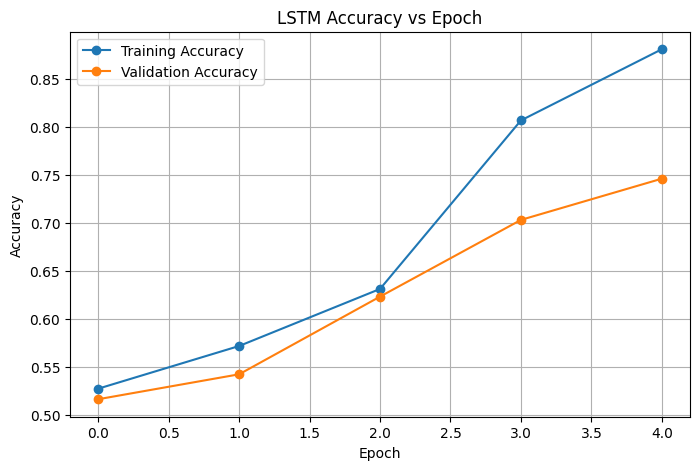

In [11]:
# Cell 11: Plot Accuracy vs Epoch

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("LSTM Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


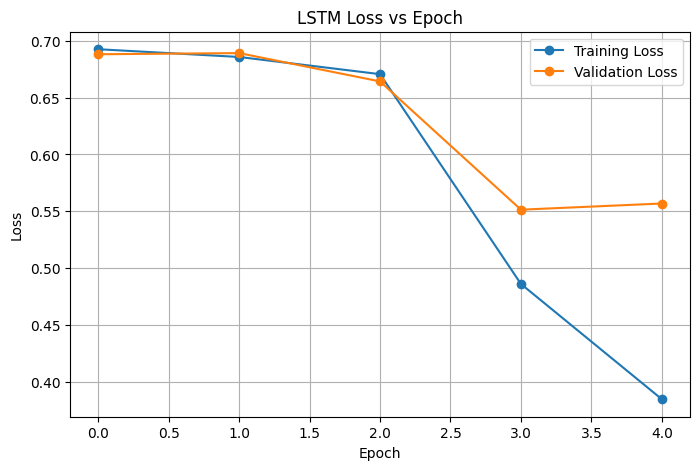

In [12]:
# Cell 12: Plot Loss vs Epoch

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("LSTM Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [13]:
# Cell 13: Evaluate on Test Dataset

test_loss, test_accuracy = model.evaluate(
    X_test_padded,
    y_test,
    verbose=1
)

print("Test Loss     :", test_loss)
print("Test Accuracy :", test_accuracy)


32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7260 - loss: 0.5452
Test Loss     : 0.5451812744140625
Test Accuracy : 0.7260000109672546


In [14]:
# Cell 14: Calculate Accuracy, Precision, Recall and F1-score

y_probability = model.predict(
    X_test_padded,
    verbose=0
).ravel()

y_pred = (y_probability >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)


Accuracy : 0.726
Precision: 0.6779359430604982
Recall   : 0.8037974683544303
F1 Score : 0.7355212355212355


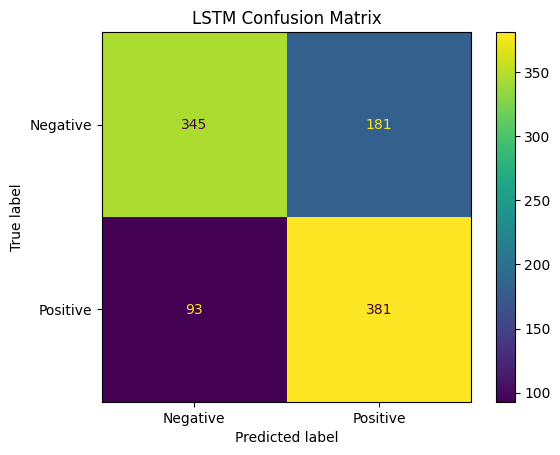

Confusion Matrix:
[[345 181]
 [ 93 381]]


In [15]:
# Cell 15: Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()
plt.title("LSTM Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)


In [16]:
# Cell 16: Display Some Actual vs Predicted Labels

for i in range(10):
    actual = "Positive" if y_test[i] == 1 else "Negative"
    predicted = "Positive" if y_pred[i] == 1 else "Negative"

    print(
        f"Review {i+1}: Actual = {actual}, "
        f"Predicted = {predicted}, "
        f"Probability = {y_probability[i]:.3f}"
    )


Review 1: Actual = Negative, Predicted = Negative, Probability = 0.062
Review 2: Actual = Positive, Predicted = Positive, Probability = 0.784
Review 3: Actual = Positive, Predicted = Positive, Probability = 0.622
Review 4: Actual = Negative, Predicted = Positive, Probability = 0.559
Review 5: Actual = Positive, Predicted = Positive, Probability = 0.820
Review 6: Actual = Positive, Predicted = Negative, Probability = 0.079
Review 7: Actual = Positive, Predicted = Positive, Probability = 0.514
Review 8: Actual = Negative, Predicted = Negative, Probability = 0.172
Review 9: Actual = Negative, Predicted = Negative, Probability = 0.388
Review 10: Actual = Positive, Predicted = Negative, Probability = 0.435


In [17]:
# Cell 17: Prepare New Reviews for Prediction

def prepare_review(review):
    words = review.lower().split()
    sequence = []

    for word in words:
        if word in word_index:
            index = word_index[word] + 3

            if index < NUM_WORDS:
                sequence.append(index)

    padded = pad_sequences(
        [sequence],
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    return padded


def predict_sentiment(review):
    processed_review = prepare_review(review)

    probability = float(
        model.predict(processed_review, verbose=0)[0][0]
    )

    sentiment = "Positive" if probability >= 0.5 else "Negative"

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("Positive Probability:", round(probability, 4))


In [18]:
# Cell 18: Test Sample Reviews

review1 = "This movie was amazing and I really enjoyed every part of it"
review2 = "The movie was boring, disappointing and not worth watching"

predict_sentiment(review1)

print()

predict_sentiment(review2)


Review: This movie was amazing and I really enjoyed every part of it
Predicted Sentiment: Positive
Positive Probability: 0.8829

Review: The movie was boring, disappointing and not worth watching
Predicted Sentiment: Negative
Positive Probability: 0.0619


In [19]:
# Cell 19: Save the Trained Model

model.save("lstm_sentiment_model.keras")

print("LSTM model saved successfully as:")
print("lstm_sentiment_model.keras")


LSTM model saved successfully as:
lstm_sentiment_model.keras
